In [1]:
import datetime
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import seaborn as sns

from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.helper_save_function import save_with_meta
from djimaging.user.amacrine_cells_neuromodulation.notebooks.function_utils.utils import pad_to_length, check_array_lengths
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
current_date = datetime.date.today().strftime("%Y%m%d")
print(current_date)

20261020


In [3]:
df = pd.read_pickle(f"../datasets/Processed/Averages_gChirpFieldsFiltered_20261013.pkl")
df.shape

(3784, 48)

In [4]:
# Determine the set of cond2 values per (date, field) group
group_conditions = df.groupby(["date", "field"])["cond2"].apply(lambda s: set(s.unique()))

# Identify which groups are C1/C2 vs C1/DETANO
c2_groups = group_conditions[group_conditions == {"C1", "C2"}].index
detano_groups = group_conditions[group_conditions == {"C1", "DETANO"}].index

# Build a boolean mask using the (date, field) MultiIndex
df_idx = df.set_index(["date", "field"]).index

df_c2 = df[df_idx.isin(c2_groups)]
df_detano = df[df_idx.isin(detano_groups)]

print(f"C1/C2 groups: {len(c2_groups)}")
print(f"C1/DETANO groups: {len(detano_groups)}")

C1/C2 groups: 5
C1/DETANO groups: 5


# C1/C2

In [5]:
print(df_c2.shape)
print(sum(df_c2["cluster_gchirp"].value_counts().sort_index() / 2))

(1858, 48)
841.0


In [6]:
df_cluster0 = df_c2[df_c2["cluster_gchirp"] == 0]
print(df_cluster0.shape)

(336, 48)


In [7]:
df_c1_cluster0 = df_cluster0[df_cluster0["cond2"] == "C1"]
df_c2_cluster0 = df_cluster0[df_cluster0["cond2"] == "C2"]

print(df_c1_cluster0.shape)
print(df_c2_cluster0.shape)

(168, 48)
(168, 48)


In [8]:
sf = 500  # sampling frequency (Hz)

features = {
    "on":        [round(sf*2),  round(sf*5)],
    "off":       [round(sf*5),  round(sf*8)],
    "low_freq":  [round(sf*10), round(sf*13)],
    "high_freq": [round(sf*15), round(sf*18)],
    "low_cont":  [round(sf*20), round(sf*23)],
    "high_cont": [round(sf*25), round(sf*28)],
}

trace_col = "average_norm_gChirp"

In [9]:
def safe_delta(a,b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    if len(a) != len(b) or len(a) < 2:
        return np.nan

    mask = ~np.isnan(a) & ~np.isnan(b)
    a, b = a[mask], b[mask]
    if len(a) < 2 or np.std(a) == 0 or np.std(b) == 0:
        return np.nan

    diff = np.mean(b) - np.mean(a)
    
    return diff

def feature_deltas(trace0, trace1, features):

    trace0 = np.asarray(trace0, dtype=float)
    trace1 = np.asarray(trace1, dtype=float)
    return {name: safe_delta(trace0[start:end], trace1[start:end])
            for name, (start, end) in features.items()}

In [10]:
roi_id_col = None

key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

# If roi_id was moved into the index in Cell 2, bring it back as a column
c1_k = df_c1_cluster0.reset_index() if roi_id_col is not None else df_c1_cluster0
c2_k = df_c2_cluster0.reset_index() if roi_id_col is not None else df_c2_cluster0

missing = [k for k in key_cols if k not in c1_k.columns or k not in c2_k.columns]
assert not missing, f"Missing key columns: {missing}"

# Keys that are identical in both dataframes for every ROI are stored once;
# keys that differ are stored as <key>_c1 and <key>_c2
differing = [k for k in key_cols
             if not (c1_k[k].astype(str).values == c2_k[k].astype(str).values).all()]
shared = [k for k in key_cols if k not in differing]
print("Shared keys:   ", shared)
print("Differing keys:", differing)

results = []
for i in range(len(c1_k)):
    row1 = c1_k.iloc[i]
    row2 = c2_k.iloc[i]

    rec = {k: row1[k] for k in shared}
    for k in differing:
        rec[f"{k}_c1"] = row1[k]
        rec[f"{k}_c2"] = row2[k]

    rec.update(feature_deltas(row1[trace_col], row2[trace_col], features))
    results.append(rec)

index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "c2")]
df_delta = pd.DataFrame(results).set_index(index_cols)
df_delta_flat = df_delta.reset_index()

assert df_delta.index.is_unique, "Primary keys do not uniquely identify ROIs!"
df_delta_flat.head()

Shared keys:    ['experimenter', 'date', 'exp_num', 'raw_id', 'field', 'region', 'cond1', 'roi_id', 'cluster_gchirp']
Differing keys: []


,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,Salomon,2025-09-08,2,1,XY7,RR,n,3,0.0,-0.112138,-0.039882,0.102649,-0.012580,0.056295,0.054213
1,Salomon,2025-09-08,2,1,XY7,RR,n,5,0.0,-0.233355,-0.006318,-0.083044,-0.155222,0.003068,-0.219347
2,Salomon,2025-09-08,2,1,XY7,RR,n,6,0.0,-0.165112,-0.074767,-0.036368,-0.128967,-0.071891,-0.088379
3,Salomon,2025-09-08,2,1,XY7,RR,n,8,0.0,-0.159929,-0.025601,0.006082,-0.028225,-0.013685,-0.015848
4,Salomon,2025-09-08,2,1,XY7,RR,n,9,0.0,-0.236703,-0.032196,-0.055789,-0.122197,-0.053161,-0.043347


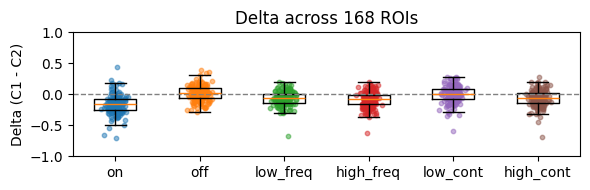

In [11]:
fig, ax = plt.subplots(figsize=(6, 2))

data = [df_delta[f].dropna().values for f in features]
ax.boxplot(data, tick_labels=list(features), showfliers=False)

for i, d in enumerate(data, start=1):
    jitter = np.random.normal(0, 0.06, size=len(d))
    ax.scatter(np.full(len(d), i) + jitter, d, s=10, alpha=0.5)

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Delta (C1 - C2)")
ax.set_title(f"Delta across {len(df_delta)} ROIs")
ax.set_ylim(-1,1)
plt.tight_layout()
plt.show()

In [12]:
cluster_ids = df["cluster_gchirp"].unique()
cluster_ids = cluster_ids[~np.isnan(cluster_ids)].astype(np.int32)
cluster_ids = np.sort(cluster_ids)

n_clusters = len(cluster_ids)
print(f"N clusters: {n_clusters}")
print(cluster_ids)

N clusters: 8
[0 1 2 3 4 5 6 7]


In [13]:
n_rois_c1 = []
n_rois_c2 = []

for i in cluster_ids:

    df_cluster = df_c2[df_c2["cluster_gchirp"] == i]

    #n_rois.append(df_cluster.shape[0] / 2)

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_c2_cluster = df_cluster[df_cluster["cond2"] == "C2"]

    n_rois_c1.append(df_c1_cluster.shape[0])
    n_rois_c2.append(df_c2_cluster.shape[0])
    
print(sum(n_rois_c1))
print(sum(n_rois_c2))

841
841


In [14]:
delta_list = []

for i in cluster_ids:

    df_cluster = df_c2[df_c2["cluster_gchirp"] == i]

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_c2_cluster = df_cluster[df_cluster["cond2"] == "C2"]

    max_end = max(end for _, end in features.values())

    len_c1 = df_c1_cluster[trace_col].apply(lambda x: len(np.asarray(x)))
    len_c2 = df_c2_cluster[trace_col].apply(lambda x: len(np.asarray(x)))

    too_short = (len_c1 < max_end) | (len_c2 < max_end)

    if too_short.sum() > 0:
        raise ValueError("One of the traces is too short")

    key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

    # If roi_id was moved into the index in Cell 2, bring it back as a column
    c1_k = df_c1_cluster.reset_index() if roi_id_col is not None else df_c1_cluster
    c2_k = df_c2_cluster.reset_index() if roi_id_col is not None else df_c2_cluster
    
    missing = [k for k in key_cols if k not in c1_k.columns or k not in c2_k.columns]
    assert not missing, f"Missing key columns: {missing}"
    
    # Keys that are identical in both dataframes for every ROI are stored once;
    # keys that differ are stored as <key>_c1 and <key>_c2
    differing = [k for k in key_cols
                 if not (c1_k[k].astype(str).values == c2_k[k].astype(str).values).all()]
    shared = [k for k in key_cols if k not in differing]
    # print("Shared keys:   ", shared)
    # print("Differing keys:", differing)
    
    results = []
    for j in range(len(c1_k)):
        row1 = c1_k.iloc[j]
        row2 = c2_k.iloc[j]
    
        rec = {k: row1[k] for k in shared}
        for k in differing:
            rec[f"{k}_c1"] = row1[k]
            rec[f"{k}_c2"] = row2[k]
    
        rec.update(feature_deltas(row1[trace_col], row2[trace_col], features))
        results.append(rec)
    
    index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "c2")]
    df_delta = pd.DataFrame(results).set_index(index_cols)
    df_delta_flat = df_delta.reset_index()
    
    assert df_delta.index.is_unique, "Primary keys do not uniquely identify ROIs!"
    #df_delta_flat.head()

    delta_list.append(df_delta_flat)
df_deltas = pd.concat(delta_list, ignore_index=True)

df_deltas.head()

,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,Salomon,2025-09-08,2,1,XY7,RR,n,3,0.0,-0.112138,-0.039882,0.102649,-0.012580,0.056295,0.054213
1,Salomon,2025-09-08,2,1,XY7,RR,n,5,0.0,-0.233355,-0.006318,-0.083044,-0.155222,0.003068,-0.219347
2,Salomon,2025-09-08,2,1,XY7,RR,n,6,0.0,-0.165112,-0.074767,-0.036368,-0.128967,-0.071891,-0.088379
3,Salomon,2025-09-08,2,1,XY7,RR,n,8,0.0,-0.159929,-0.025601,0.006082,-0.028225,-0.013685,-0.015848
4,Salomon,2025-09-08,2,1,XY7,RR,n,9,0.0,-0.236703,-0.032196,-0.055789,-0.122197,-0.053161,-0.043347


In [15]:
df_deltas["cluster_gchirp"].value_counts().sort_index()

cluster_gchirp
0.0    168
1.0    109
2.0     75
3.0    183
4.0     27
5.0     83
6.0    153
7.0     43
Name: count, dtype: int64

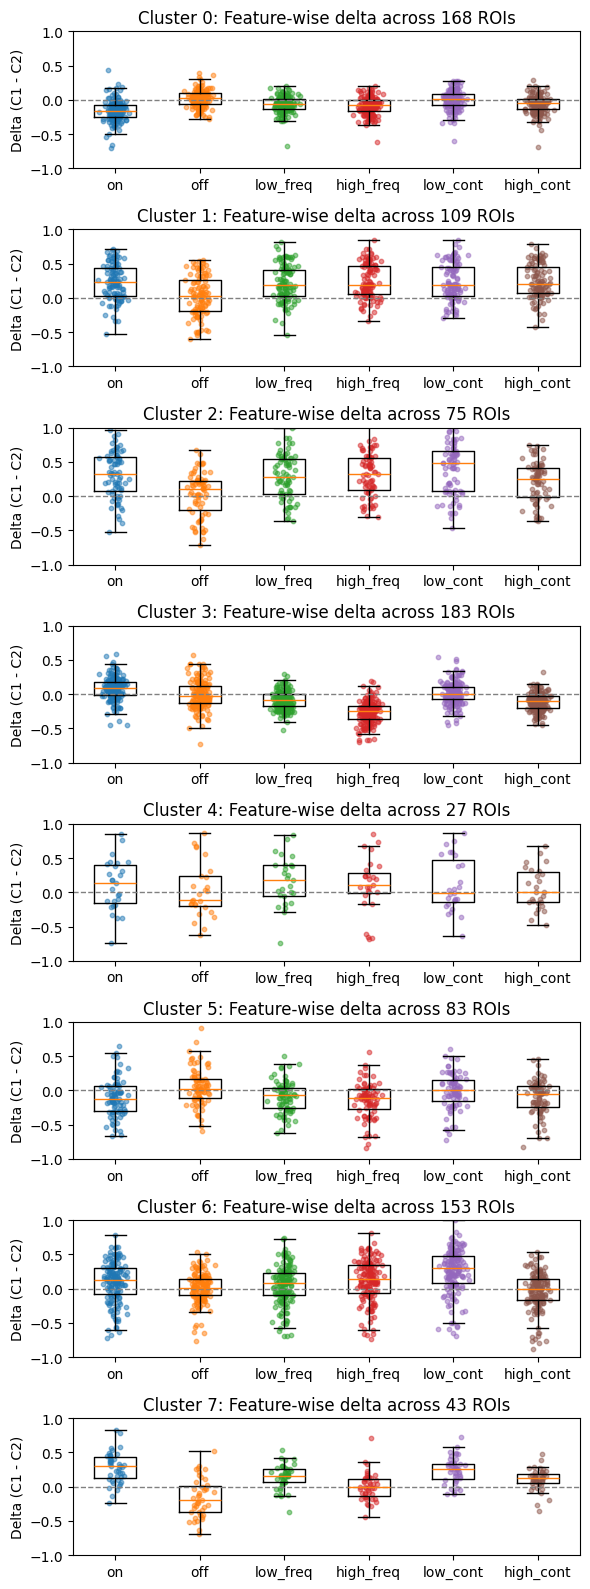

In [16]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(6, 2 * n_clusters))

for i in cluster_ids:

    df_delta_cluster = df_deltas[df_deltas["cluster_gchirp"] == i]

    data = [df_delta_cluster[f].dropna().values for f in features]
    axs[i].boxplot(data, tick_labels=list(features), showfliers=False)
    
    for j, d in enumerate(data, start=1):
        jitter = np.random.normal(0, 0.06, size=len(d))
        axs[i].scatter(np.full(len(d), j) + jitter, d, s=10, alpha=0.5)
    
    axs[i].axhline(0, color="grey", linestyle="--", linewidth=1)
    axs[i].set_ylabel("Delta (C1 - C2)")
    axs[i].set_title(f"Cluster {i}: Feature-wise delta across {len(df_delta_cluster)} ROIs")
    axs[i].set_ylim(-1,1)

plt.tight_layout()
plt.savefig(f"../plots/clustering/C1C2_feature_delta_boxplot_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

In [17]:
columns = ["cluster_gchirp", "on", "off", "low_freq", "high_freq", "low_cont", "high_cont"]
columns

['cluster_gchirp',
 'on',
 'off',
 'low_freq',
 'high_freq',
 'low_cont',
 'high_cont']

In [18]:
mean_delta = []
std_delta = []

for row, i in enumerate(cluster_ids):

    df_delta_cluster = df_deltas[
        df_deltas["cluster_gchirp"] == i
    ]

    mean_delta_cluster = df_delta_cluster[columns].mean(axis=0)
    std_delta_cluster = df_delta_cluster[columns].std(axis=0)

    # Convert to DataFrames with one row
    heatmap_mean_cluster = pd.DataFrame(
        [mean_delta_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    heatmap_std_cluster = pd.DataFrame(
        [std_delta_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    mean_delta.append(heatmap_mean_cluster)
    std_delta.append(heatmap_std_cluster)

df_mean_delta = pd.concat(mean_delta)
df_mean_delta = df_mean_delta.reset_index(drop=True)

df_std_delta = pd.concat(std_delta)
df_std_delta = df_std_delta.reset_index(drop=True)

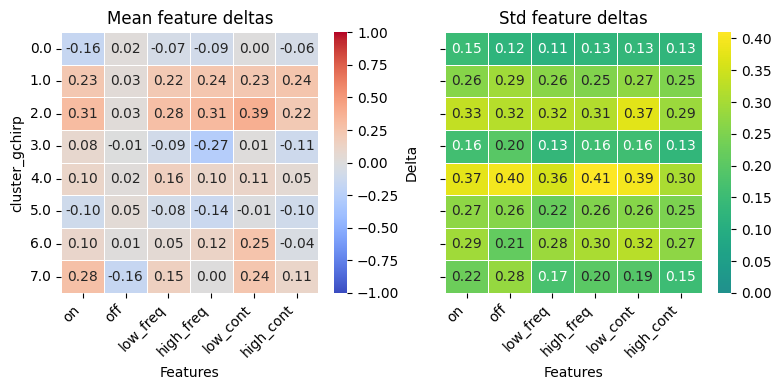

In [19]:
# Select the six columns to plot
columns_plot = df_mean_delta.columns.drop("cluster_gchirp")
data_mean = df_mean_delta[columns_plot]
data_std = df_std_delta[columns_plot]

# Create heatmap
fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

sns.heatmap(
    data_mean,
    ax=ax[0],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Delta"},
    yticklabels=df_mean_delta["cluster_gchirp"]
)

sns.heatmap(
    data_std,
    ax=ax[1],
    cmap="viridis",
    vmin=0,
    vmax=data_std.values.max(),
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    #cbar_kws={"label": "Std"},
    yticklabels=df_std_delta["cluster_gchirp"]
)

ax[0].set_ylabel("cluster_gchirp")
ax[0].set_title("Mean feature deltas")
ax[1].set_title("Std feature deltas")

for i in ax:

    # Label axes
    i.set_xlabel("Features")
    i.set_xticklabels(columns_plot, rotation=45, ha="right")
    i.set_yticklabels(df_mean_delta["cluster_gchirp"], rotation=0)

plt.tight_layout()
plt.savefig(f"../plots/clustering/C1C2_feature_deltas_mean_heatmap_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

# C1 / DETA/NO

In [20]:
print(df_detano.shape)
print(sum(df_detano["cluster_gchirp"].value_counts().sort_index() / 2))

(1926, 48)
696.0


In [21]:
df_cluster0 = df_detano[df_detano["cluster_gchirp"] == 0]
print(df_cluster0.shape)

(460, 48)


In [22]:
df_c1_cluster0 = df_cluster0[df_cluster0["cond2"] == "C1"]
df_no_cluster0 = df_cluster0[df_cluster0["cond2"] == "DETANO"]

print(df_c1_cluster0.shape)
print(df_no_cluster0.shape)

(230, 48)
(230, 48)


In [23]:
roi_id_col = None

key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

# If roi_id was moved into the index in Cell 2, bring it back as a column
c1_k = df_c1_cluster0.reset_index() if roi_id_col is not None else df_c1_cluster0
no_k = df_no_cluster0.reset_index() if roi_id_col is not None else df_no_cluster0

missing = [k for k in key_cols if k not in c1_k.columns or k not in no_k.columns]
assert not missing, f"Missing key columns: {missing}"

# Keys that are identical in both dataframes for every ROI are stored once;
# keys that differ are stored as <key>_c1 and <key>_c2
differing = [k for k in key_cols
             if not (c1_k[k].astype(str).values == no_k[k].astype(str).values).all()]
shared = [k for k in key_cols if k not in differing]
print("Shared keys:   ", shared)
print("Differing keys:", differing)

results = []
for i in range(len(c1_k)):
    row1 = c1_k.iloc[i]
    row2 = no_k.iloc[i]

    rec = {k: row1[k] for k in shared}
    for k in differing:
        rec[f"{k}_c1"] = row1[k]
        rec[f"{k}_no"] = row2[k]

    rec.update(feature_deltas(row1[trace_col], row2[trace_col], features))
    results.append(rec)

index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "no")]
df_delta = pd.DataFrame(results).set_index(index_cols)
df_delta_flat = df_delta.reset_index()

assert df_delta.index.is_unique, "Primary keys do not uniquely identify ROIs!"
df_delta_flat.head()

Shared keys:    ['experimenter', 'date', 'exp_num', 'raw_id', 'field', 'region', 'cond1', 'roi_id', 'cluster_gchirp']
Differing keys: []


,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,Salomon,2025-09-08,2,1,XY2,RR,v,164,0.0,-0.089881,-0.198065,-0.217053,-0.083811,-0.141886,-0.187074
1,Salomon,2025-09-08,2,1,XY2,RR,v,184,0.0,0.094936,-0.065362,-0.066797,-0.085422,-0.067724,-0.145972
2,Salomon,2025-09-08,2,1,XY8,RR,n,7,0.0,-0.178681,-0.145301,-0.130911,-0.125989,-0.088707,-0.075878
3,Salomon,2025-09-08,2,1,XY8,RR,n,12,0.0,-0.098739,-0.056056,-0.116188,-0.035823,-0.046411,-0.051553
4,Salomon,2025-09-08,2,1,XY8,RR,n,13,0.0,-0.182700,-0.152749,-0.250111,-0.126758,-0.161222,-0.188778


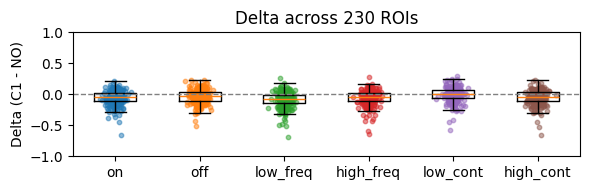

In [24]:
fig, ax = plt.subplots(figsize=(6, 2))

data = [df_delta[f].dropna().values for f in features]
ax.boxplot(data, tick_labels=list(features), showfliers=False)

for i, d in enumerate(data, start=1):
    jitter = np.random.normal(0, 0.06, size=len(d))
    ax.scatter(np.full(len(d), i) + jitter, d, s=10, alpha=0.5)

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_ylabel("Delta (C1 - NO)")
ax.set_title(f"Delta across {len(df_delta)} ROIs")
ax.set_ylim(-1,1)
plt.tight_layout()
plt.show()

In [25]:
cluster_ids = df["cluster_gchirp"].unique()
cluster_ids = cluster_ids[~np.isnan(cluster_ids)].astype(np.int32)
cluster_ids = np.sort(cluster_ids)

n_clusters = len(cluster_ids)
print(f"N clusters: {n_clusters}")
print(cluster_ids)

N clusters: 8
[0 1 2 3 4 5 6 7]


In [27]:
n_rois_c1 = []
n_rois_no = []

for i in cluster_ids:

    df_cluster = df_detano[df_detano["cluster_gchirp"] == i]

    #n_rois.append(df_cluster.shape[0] / 2)

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_no_cluster = df_cluster[df_cluster["cond2"] == "DETANO"]

    n_rois_c1.append(df_c1_cluster.shape[0])
    n_rois_no.append(df_no_cluster.shape[0])
    
print(sum(n_rois_c1))
print(sum(n_rois_no))

696
696


In [28]:
delta_list_no = []

for i in cluster_ids:

    df_cluster = df_detano[df_detano["cluster_gchirp"] == i]

    df_c1_cluster = df_cluster[df_cluster["cond2"] == "C1"]
    df_no_cluster = df_cluster[df_cluster["cond2"] == "DETANO"]

    max_end = max(end for _, end in features.values())

    len_c1 = df_c1_cluster[trace_col].apply(lambda x: len(np.asarray(x)))
    len_no = df_no_cluster[trace_col].apply(lambda x: len(np.asarray(x)))

    too_short = (len_c1 < max_end) | (len_no < max_end)

    if too_short.sum() > 0:
        raise ValueError("One of the traces is too short")

    key_cols = ["experimenter", "date", "exp_num", "raw_id", "field",
            "region", "cond1", "roi_id", "cluster_gchirp"]

    # If roi_id was moved into the index in Cell 2, bring it back as a column
    c1_k = df_c1_cluster.reset_index() if roi_id_col is not None else df_c1_cluster
    no_k = df_no_cluster.reset_index() if roi_id_col is not None else df_no_cluster
    
    missing = [k for k in key_cols if k not in c1_k.columns or k not in no_k.columns]
    assert not missing, f"Missing key columns: {missing}"
    
    # Keys that are identical in both dataframes for every ROI are stored once;
    # keys that differ are stored as <key>_c1 and <key>_c2
    differing = [k for k in key_cols
                 if not (c1_k[k].astype(str).values == no_k[k].astype(str).values).all()]
    shared = [k for k in key_cols if k not in differing]
    # print("Shared keys:   ", shared)
    # print("Differing keys:", differing)
    
    results = []
    for j in range(len(c1_k)):
        row1 = c1_k.iloc[j]
        row2 = no_k.iloc[j]
    
        rec = {k: row1[k] for k in shared}
        for k in differing:
            rec[f"{k}_c1"] = row1[k]
            rec[f"{k}_no"] = row2[k]
    
        rec.update(feature_deltas(row1[trace_col], row2[trace_col], features))
        results.append(rec)
    
    index_cols = shared + [f"{k}_{s}" for k in differing for s in ("c1", "no")]
    df_delta = pd.DataFrame(results).set_index(index_cols)
    df_delta_flat = df_delta.reset_index()
    
    assert df_delta.index.is_unique, "Primary keys do not uniquely identify ROIs!"
    #df_delta_flat.head()

    delta_list_no.append(df_delta_flat)
df_deltas_no = pd.concat(delta_list_no, ignore_index=True)

df_deltas_no.head()

,experimenter,date,exp_num,raw_id,field,region,cond1,roi_id,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,Salomon,2025-09-08,2,1,XY2,RR,v,164,0.0,-0.089881,-0.198065,-0.217053,-0.083811,-0.141886,-0.187074
1,Salomon,2025-09-08,2,1,XY2,RR,v,184,0.0,0.094936,-0.065362,-0.066797,-0.085422,-0.067724,-0.145972
2,Salomon,2025-09-08,2,1,XY8,RR,n,7,0.0,-0.178681,-0.145301,-0.130911,-0.125989,-0.088707,-0.075878
3,Salomon,2025-09-08,2,1,XY8,RR,n,12,0.0,-0.098739,-0.056056,-0.116188,-0.035823,-0.046411,-0.051553
4,Salomon,2025-09-08,2,1,XY8,RR,n,13,0.0,-0.182700,-0.152749,-0.250111,-0.126758,-0.161222,-0.188778


In [29]:
df_deltas_no["cluster_gchirp"].value_counts().sort_index()

cluster_gchirp
0.0    230
1.0      1
2.0     46
3.0    209
4.0     60
5.0     43
6.0     83
7.0     24
Name: count, dtype: int64

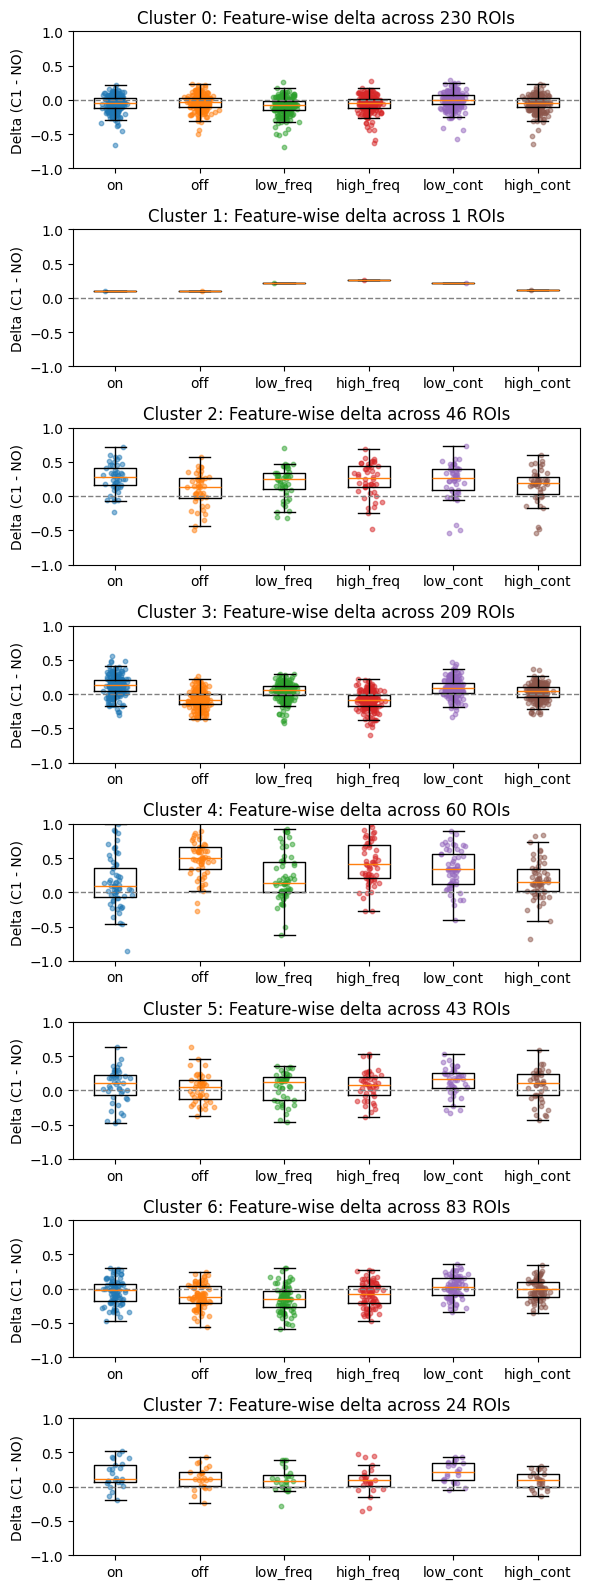

In [44]:
fig, axs = plt.subplots(n_clusters, 1, figsize=(6, 2 * n_clusters))

for i in cluster_ids:

    df_delta_cluster = df_deltas_no[df_deltas_no["cluster_gchirp"] == i]

    data = [df_delta_cluster[f].dropna().values for f in features]
    axs[i].boxplot(data, tick_labels=list(features), showfliers=False)
    
    for j, d in enumerate(data, start=1):
        jitter = np.random.normal(0, 0.06, size=len(d))
        axs[i].scatter(np.full(len(d), j) + jitter, d, s=10, alpha=0.5)
    
    axs[i].axhline(0, color="grey", linestyle="--", linewidth=1)
    axs[i].set_ylabel("Delta (C1 - NO)")
    axs[i].set_title(f"Cluster {i}: Feature-wise delta across {len(df_delta_cluster)} ROIs")
    axs[i].set_ylim(-1,1)

plt.tight_layout()
plt.savefig(f"../plots/clustering/C1NO_feature_deltas_boxplot_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

In [46]:
mean_delta_no = []
std_delta_no = []

for row, i in enumerate(cluster_ids):

    df_delta_cluster = df_deltas_no[
        df_deltas_no["cluster_gchirp"] == i
    ]

    mean_delta_cluster = df_delta_cluster[columns].mean(axis=0)
    std_delta_cluster = df_delta_cluster[columns].std(axis=0)

    # Convert to DataFrames with one row
    heatmap_mean_cluster = pd.DataFrame(
        [mean_delta_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    heatmap_std_cluster = pd.DataFrame(
        [std_delta_cluster.values],
        columns=columns,
        index=[f"cluster_gchirp {i}"]
    )

    mean_delta_no.append(heatmap_mean_cluster)
    std_delta_no.append(heatmap_std_cluster)

df_mean_delta_no = pd.concat(mean_delta_no)
df_mean_delta_no = df_mean_delta_no.reset_index(drop=True)

df_std_delta_no = pd.concat(std_delta_no)
df_std_delta_no = df_std_delta_no.reset_index(drop=True)

In [47]:
df_mean_delta_no

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,-0.054923,-0.039366,-0.092914,-0.059789,-0.006331,-0.052923
1,1.0,0.105467,0.095029,0.210682,0.256550,0.223914,0.111592
2,2.0,0.268271,0.096117,0.192515,0.241381,0.219631,0.152833
3,3.0,0.126672,-0.073814,0.042635,-0.091323,0.094786,0.031324
4,4.0,0.143356,0.506746,0.211259,0.432431,0.333308,0.188206
5,5.0,0.067533,0.031129,0.040580,0.071398,0.135306,0.068593
6,6.0,-0.048808,-0.113321,-0.149360,-0.088795,0.018626,-0.012556
7,7.0,0.174255,0.121363,0.106011,0.094224,0.220120,0.095834


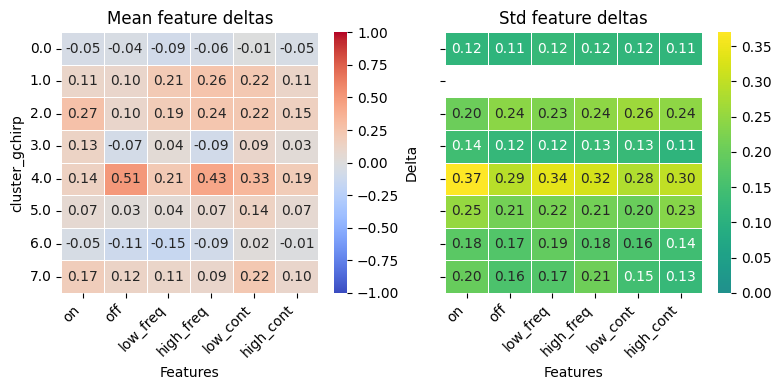

In [48]:
# Select the six columns to plot
columns_plot = df_mean_delta_no.columns.drop("cluster_gchirp")
data_mean_no = df_mean_delta_no[columns_plot]
data_std_no = df_std_delta_no[columns_plot]

# Create heatmap
fig, ax = plt.subplots(1, 2, figsize=(8, 4), sharey=True)

sns.heatmap(
    data_mean_no,
    ax=ax[0],
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Delta"},
    yticklabels=df_mean_delta_no["cluster_gchirp"]
)

sns.heatmap(
    data_std_no,
    ax=ax[1],
    cmap="viridis",
    vmin=0,
    vmax=np.nanmax(data_std_no),
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    #cbar_kws={"label": "Std"},
    yticklabels=df_std_delta_no["cluster_gchirp"]
)

ax[0].set_ylabel("cluster_gchirp")
ax[0].set_title("Mean feature deltas")
ax[1].set_title("Std feature deltas")

for i in ax:

    # Label axes
    i.set_xlabel("Features")
    i.set_xticklabels(columns_plot, rotation=45, ha="right")
    i.set_yticklabels(df_mean_delta_no["cluster_gchirp"], rotation=0)

plt.tight_layout()
plt.savefig(f"../plots/clustering/C1NO_feature_deltas_mean_heatmap_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()

# C2 / DETANO

In [49]:
df_mean_delta

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,-0.161631,0.016344,-0.065372,-0.088149,0.003245,-0.063723
1,1.0,0.229653,0.034590,0.217319,0.240855,0.231449,0.242985
2,2.0,0.311594,0.025355,0.284756,0.312516,0.389494,0.217851
3,3.0,0.083463,-0.006743,-0.092472,-0.266324,0.010339,-0.114103
4,4.0,0.103333,0.023045,0.162820,0.102676,0.110394,0.049008
5,5.0,-0.103678,0.045116,-0.083632,-0.138942,-0.011128,-0.099028
6,6.0,0.096469,0.013020,0.054299,0.118383,0.254025,-0.036939
7,7.0,0.279960,-0.159355,0.148719,0.002734,0.242156,0.107148


In [50]:
df_mean_delta_no

,cluster_gchirp,on,off,low_freq,high_freq,low_cont,high_cont
0,0.0,-0.054923,-0.039366,-0.092914,-0.059789,-0.006331,-0.052923
1,1.0,0.105467,0.095029,0.210682,0.256550,0.223914,0.111592
2,2.0,0.268271,0.096117,0.192515,0.241381,0.219631,0.152833
3,3.0,0.126672,-0.073814,0.042635,-0.091323,0.094786,0.031324
4,4.0,0.143356,0.506746,0.211259,0.432431,0.333308,0.188206
5,5.0,0.067533,0.031129,0.040580,0.071398,0.135306,0.068593
6,6.0,-0.048808,-0.113321,-0.149360,-0.088795,0.018626,-0.012556
7,7.0,0.174255,0.121363,0.106011,0.094224,0.220120,0.095834


In [51]:
columns_plot

Index(['on', 'off', 'low_freq', 'high_freq', 'low_cont', 'high_cont'], dtype='object')

In [52]:
df_mean_delta_c2_no = df_mean_delta[columns_plot] - df_mean_delta_no[columns_plot]
df_mean_delta_c2_no

,on,off,low_freq,high_freq,low_cont,high_cont
0,-0.106708,0.055710,0.027543,-0.028361,0.009576,-0.010799
1,0.124187,-0.060440,0.006637,-0.015695,0.007535,0.131393
2,0.043323,-0.070763,0.092241,0.071134,0.169863,0.065019
3,-0.043208,0.067071,-0.135107,-0.175001,-0.084447,-0.145427
4,-0.040023,-0.483702,-0.048439,-0.329755,-0.222914,-0.139198
5,-0.171212,0.013987,-0.124212,-0.210340,-0.146433,-0.167620
6,0.145278,0.126340,0.203658,0.207178,0.235399,-0.024383
7,0.105706,-0.280718,0.042708,-0.091490,0.022036,0.011314


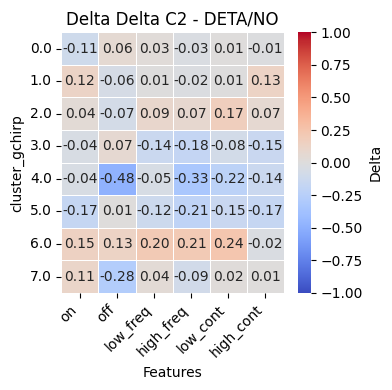

In [53]:
# Select the six columns to plot
#columns_plot = df_mean_correlation_no.columns.drop("cluster_gchirp")
data_matrix = df_mean_delta_c2_no

# Create heatmap
fig, ax = plt.subplots(1, 1, figsize=(4, 4), sharey=True)

sns.heatmap(
    data_matrix,
    ax=ax,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Delta"},
    yticklabels=df_mean_delta_no["cluster_gchirp"]
)

ax.set_ylabel("cluster_gchirp")
ax.set_title("Delta Delta C2 - DETA/NO")

ax.set_xlabel("Features")
ax.set_xticklabels(columns_plot, rotation=45, ha="right")
ax.set_yticklabels(df_mean_delta_no["cluster_gchirp"], rotation=0)

plt.tight_layout()
plt.savefig(f"../plots/clustering/C2NO_feature_deltas_mean_heatmap_{current_date}.png",
            dpi=300,
            bbox_inches="tight")
plt.show()